<a href="https://colab.research.google.com/github/junkim-researcher/turboquant-study1/blob/main/notebooks/exp1_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1단계: 내적 실험 (mse vs prod, 편향과 분산)

**사용법:** 메뉴 **[런타임] → [모두 실행]** (CPU 런타임으로 충분, 약 1분)

실행이 끝나면 **[파일] → [GitHub에 사본 저장]** → 저장소 `junkim-researcher/turboquant-study1`, 경로 `notebooks/exp1_colab.ipynb` 그대로 → **[확인]**

In [1]:
# 1) 코드 내려받기
!rm -rf /content/turboquant-study1
!git clone -q https://github.com/junkim-researcher/turboquant-study1.git /content/turboquant-study1
%cd /content/turboquant-study1
!git log --oneline -1

/content/turboquant-study1
aea6b57 (HEAD -> main, origin/main, origin/HEAD) 1단계: 내적 실험 (mse vs prod 편향과 분산)


In [2]:
# 2) 한글 그래프용 글꼴 설치
!apt-get -qq install -y fonts-noto-cjk > /dev/null 2>&1
!rm -rf ~/.cache/matplotlib
print('글꼴 설치 완료')

글꼴 설치 완료


In [3]:
# 3) 1단계 실험 실행 (약 10~40초)
!python exp1_inner.py

완료: 24.5초


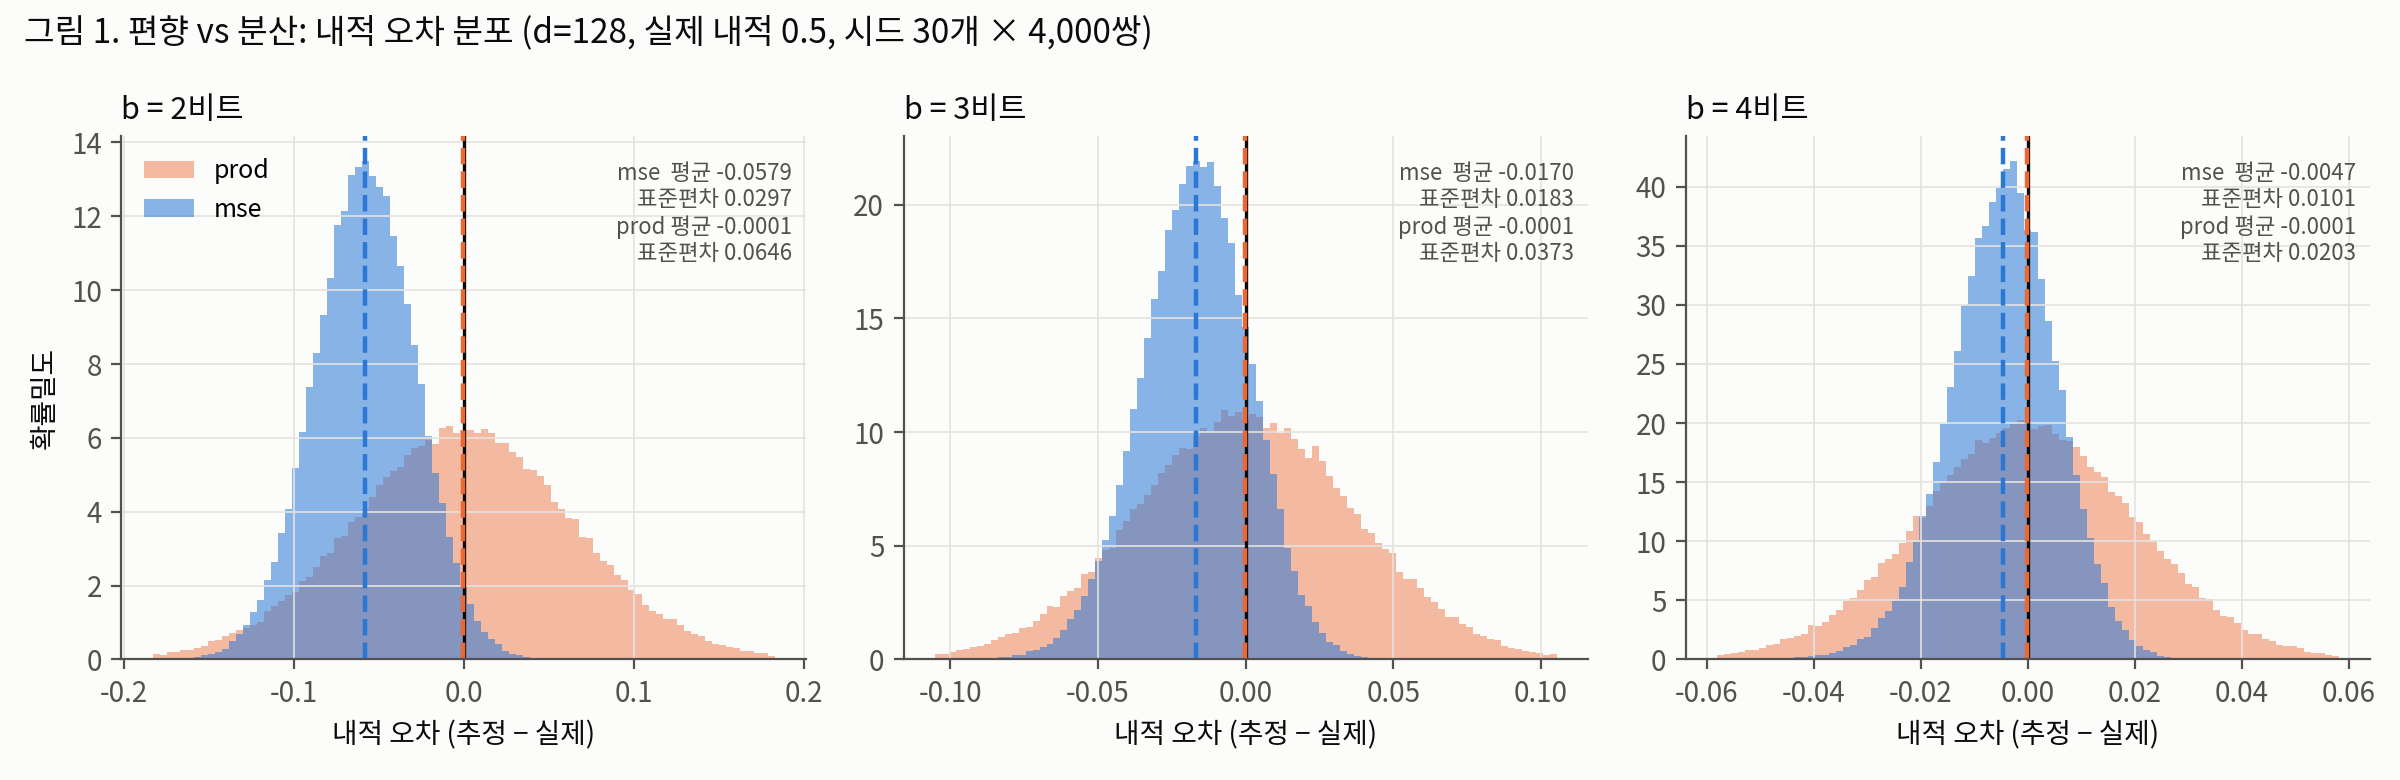

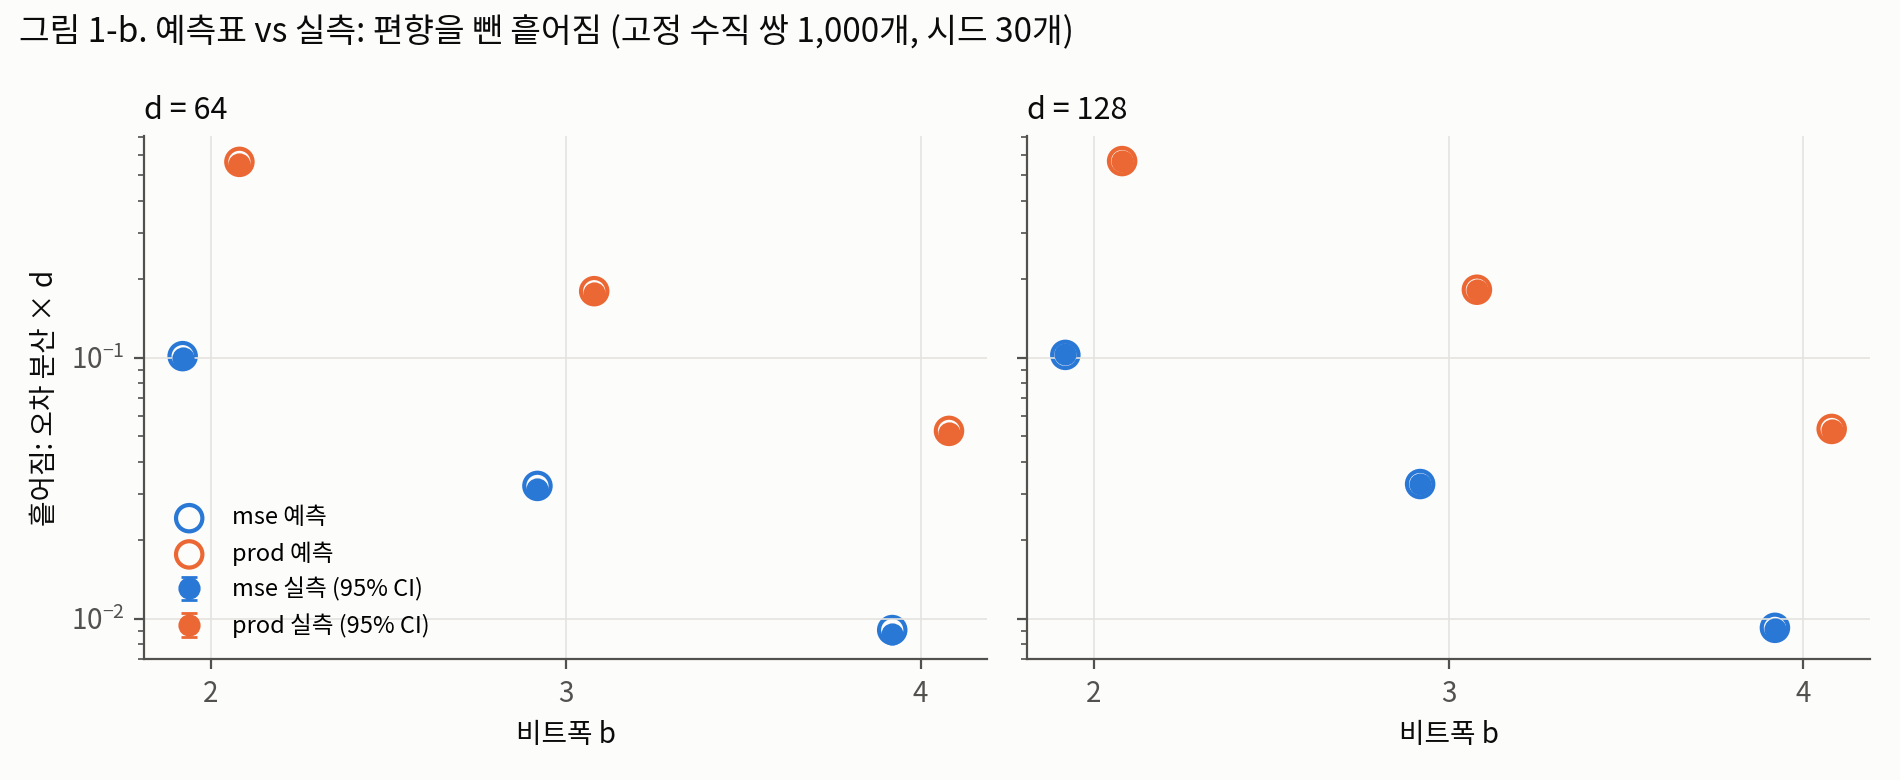

In [4]:
# 4) 그림 보기
from IPython.display import Image, display
display(Image('figures/fig1_inner_error_hist.png', width=1000))
display(Image('figures/fig1b_pred_vs_measured.png', width=900))

In [5]:
# 5) 판정 요약 (+ Claude 실행 결과와 대조)
!python summarize_exp1.py

 1단계 내적 실험 판정 요약  (시드 30개, 95% 신뢰구간은 t분포, 예측 일치 기준 ±10%)
 [1] 편향: 실제 내적 0.5일 때 상대 편향  (예측: mse = −D, prod = 0)
    d  b |   mse 실측       예측   일치 |   prod 실측           95% 신뢰구간  0 포함
   64  2 |   -11.4%   -11.5%    O |     +0.0%     [-0.1%, +0.2%]     예
   64  3 |    -3.3%    -3.3%    O |     +0.0%     [-0.1%, +0.1%]     예
   64  4 |    -0.9%    -0.9%    O |     +0.0%     [-0.0%, +0.1%]     예
  128  2 |   -11.6%   -11.6%    O |     -0.0%     [-0.1%, +0.1%]     예
  128  3 |    -3.4%    -3.4%    O |     -0.0%     [-0.1%, +0.0%]     예
  128  4 |    -0.9%    -0.9%    O |     -0.0%     [-0.0%, +0.0%]     예
--------------------------------------------------------------------------------
 [2-a] 편향을 뺀 흩어짐 × d  (고정 수직 쌍: 회전만 바뀔 때)  ← 예측표의 분산과 같은 정의
    d  b |   mse 실측   예측 D(1−D)   일치 |   prod 실측      예측   일치 |    배율
   64  2 |   0.1000      0.1014    O |    0.5501  0.5630    O |  5.50
   64  3 |   0.0314      0.0323    O |    0.1766  0.1799    O |  5.63
   64  4 |   0.0088      0.0090    O |   